# LM3 Lab — Taylor Series and Approximation

Companion notebook to **From Calculus to Kelly, LM3**. It rebuilds every exhibit and computational example in the module and the numbers in its knowledge checks, and it solves the computational practice problems; the data-driven parts use FinMind price files.

| Part | Rebuilds |
|:--|:--|
| 1 | The expansions of Exhibit 2; Taylor polynomials and the Lagrange bound (Exhibit 3, Example 1, Example 2, Example 4) |
| 2 | Total-return series with dividends and splits, verified; the case (Exhibit 1) |
| 3 | Simple vs log returns (Exhibit 4, Section 5); the two worst days (Example 3) |
| 4 | Volatility drag across sampling frequencies (Exhibit 5, Example 5, Example 6) |
| 5 | 00631L decomposition: power, drag, residual (Exhibit 6, Exhibit 7, Exhibit 8) |
| 6 | TQQQ in 2022 (Example 7) |
| 7 | Duration and convexity (Example 8, Exhibit 9) |
| 8 | Practice-problem solutions and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline. `data/` then holds FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08), 0050 cash dividends from `TaiwanStockDividendResult`, and QQQ and TQQQ closes for 2022 from `USStockPrice`, retrieved 2026-10-10. Every daily close was checked against FinMind's own `spread` column (close − previous close); the only mismatches are ex-dividend and split days, which Part 2 handles explicitly.

**Conventions (as in the module).** $T$ counts returns; a span in years is calendar days ÷ 365.25, and $A$ is the number of returns per year in the sample in use. The 0050 and 00631L series are aligned on the 2,902 days on which both funds traded.

In [1]:
import math
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import sympy as sp

DATA = Path("data")
BASE = date(2014, 10, 31)                     # last close before the first daily return
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Expansions, Taylor polynomials and the Lagrange bound

Exhibit 2 lists four Maclaurin series. SymPy reproduces their first terms.

In [2]:
x, alpha = sp.symbols("x alpha")
for fn in (sp.exp(x), sp.log(1 + x), (1 + x) ** alpha, 1 / (1 - x)):
    print(fn, "=", sp.series(fn, x, 0, 4).removeO())

exp(x) = x**3/6 + x**2/2 + x + 1
log(x + 1) = x**3/3 - x**2/2 + x
(x + 1)**alpha = alpha*x**3*(alpha - 2)*(alpha - 1)/6 + alpha*x**2*(alpha - 1)/2 + alpha*x + 1
1/(1 - x) = x**3 + x**2 + x + 1


For $\ln(1+x)$ the order-$n$ Maclaurin polynomial $T_n(x)$ keeps the first $n$ terms of the series (eq. 3.3). The Lagrange remainder (eq. 3.5) bounds its error by $|x|^{n+1}/(n+1)$ for $x\ge0$ and by $|x|^{n+1}/\big((n+1)(1+x)^{n+1}\big)$ for $-1<x<0$.

In [3]:
def taylor_log1p(x, n):
    return sum((-1) ** (k + 1) * x**k / k for k in range(1, n + 1))

def bound_log1p(x, n):
    base = 1.0 if x >= 0 else 1.0 + x
    return abs(x) ** (n + 1) / ((n + 1) * base ** (n + 1))

def taylor_exp(x, n):
    return sum(x**k / math.factorial(k) for k in range(n + 1))

xs = [-0.20, -0.10, -0.05, -0.01, 0.01, 0.05, 0.10, 0.20, 0.50]
xc = pl.col("x")
remainder = pl.DataFrame({"x": xs}).with_columns(
    xc.log1p().alias("ln(1+x)"),
    (xc - xc**2 / 2).alias("T2"),
    (xc.abs() ** 3 / (3 * pl.when(xc >= 0).then(pl.lit(1.0)).otherwise(1 + xc) ** 3)).alias("bound"),
).with_columns((pl.col("ln(1+x)") - pl.col("T2")).alias("error")).select("x", "ln(1+x)", "T2", "error", "bound")
assert (remainder["error"].abs() <= remainder["bound"]).all()
remainder   # Exhibit 3

x,ln(1+x),T2,error,bound
f64,f64,f64,f64,f64
-0.200000,-0.223144,-0.220000,-0.003144,0.005208
-0.100000,-0.105361,-0.105000,-0.000361,0.000457
-0.050000,-0.051293,-0.051250,-0.000043,0.000049
-0.010000,-0.010050,-0.010050,-0.000000,0.000000
0.010000,0.009950,0.009950,0.000000,0.000000
0.050000,0.048790,0.048750,0.000040,0.000042
0.100000,0.095310,0.095000,0.000310,0.000333
0.200000,0.182322,0.180000,0.002322,0.002667
0.500000,0.405465,0.375000,0.030465,0.041667


In [4]:
# Example 1: ln(1.05) and e^0.05 with orders 1-3 (errors are exact minus approximation)
for n in (1, 2, 3):
    print(f"n={n}:  ln T={taylor_log1p(0.05, n):.7f} err {math.log1p(0.05) - taylor_log1p(0.05, n):+.7f}"
          f"   exp T={taylor_exp(0.05, n):.7f} err {math.exp(0.05) - taylor_exp(0.05, n):+.7f}")

# Example 2: nominal 1.725% (Bank of Taiwan), expected inflation 1.8% (illustrative)
i, infl = 0.01725, 0.018
print(f"real rate: exact {(1 + i) / (1 + infl) - 1:.5%}  first order {i - infl:.5%}  "
      f"second order {(i - infl) - infl * (i - infl):.5%}")

# Example 4: doubling time and the rule of 72
for R in (0.02, 0.06, 0.08, 0.12):
    print(f"R={R:.0%}: exact {math.log(2) / math.log1p(R):6.3f}  ln2/R+ln2/2 {math.log(2) / R + math.log(2) / 2:6.3f}  "
          f"0.693/R+0.347 {0.693 / R + 0.347:6.3f}  rule of 72 {72 / (100 * R):6.3f}")
print(f"100 ln2 (1 + R/2) = 72 at R = {2 * (72 / (100 * math.log(2)) - 1):.2%}")

# knowledge checks: a monthly rate from 9% a year, and e^-0.3 with T4
print(f"(1+0.09)^(1/12) - 1: second order {0.09 / 12 - 11 / 288 * 0.09**2:.4%}, exact {1.09 ** (1 / 12) - 1:.4%}")
print(f"e^-0.3: bound {0.3**5 / 120:.4e}, actual error {math.exp(-0.3) - taylor_exp(-0.3, 4):.3e}")

n=1:  ln T=0.0500000 err -0.0012098   exp T=1.0500000 err +0.0012711
n=2:  ln T=0.0487500 err +0.0000402   exp T=1.0512500 err +0.0000211
n=3:  ln T=0.0487917 err -0.0000015   exp T=1.0512708 err +0.0000003
real rate: exact -0.07367%  first order -0.07500%  second order -0.07365%
R=2%: exact 35.003  ln2/R+ln2/2 35.004  0.693/R+0.347 34.997  rule of 72 36.000
R=6%: exact 11.896  ln2/R+ln2/2 11.899  0.693/R+0.347 11.897  rule of 72 12.000
R=8%: exact  9.006  ln2/R+ln2/2  9.011  0.693/R+0.347  9.009  rule of 72  9.000
R=12%: exact  6.116  ln2/R+ln2/2  6.123  0.693/R+0.347  6.122  rule of 72  6.000
100 ln2 (1 + R/2) = 72 at R = 7.75%
(1+0.09)^(1/12) - 1: second order 0.7191%, exact 0.7207%
e^-0.3: bound 2.0250e-05, actual error -1.928e-05


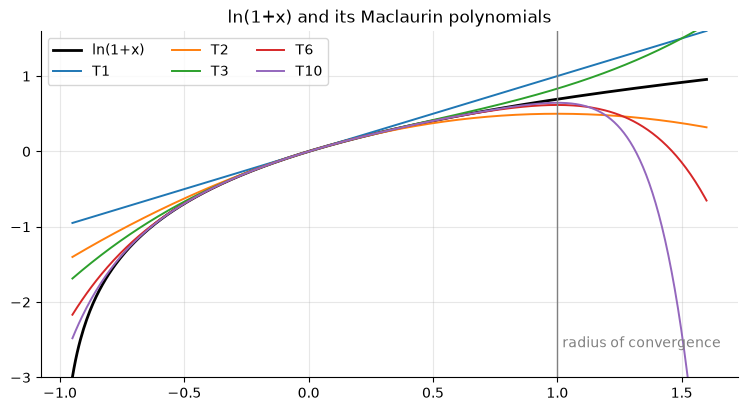

In [5]:
xg = np.linspace(-0.95, 1.6, 400)
fig, ax = plt.subplots()
ax.plot(xg, np.log1p(xg), color="black", lw=2, label="ln(1+x)")
for n in (1, 2, 3, 6, 10):
    ax.plot(xg, [taylor_log1p(v, n) for v in xg], lw=1.4, label=f"T{n}")
ax.axvline(1, color="grey", lw=1)
ax.text(1.02, -2.6, "radius of convergence", color="grey")
ax.set_ylim(-3, 1.6)
ax.set_title("ln(1+x) and its Maclaurin polynomials")
ax.legend(ncol=3)
plt.show()

## Part 2 — Total-return series, corporate actions, verification

* **0050** pays cash dividends; on an ex-date $t$ the total return is $R_t=(P_t+D_t)/P_{t-1}-1$. It split 4-for-1 effective **2025-06-18**.
* **00631L** paid no dividends in the sample and split 22-for-1 effective **2026-03-31**.
* On a split day the return is $P_t/(P_{t-1}/k)-1$, where $k$ is the split ratio ($k=4$ for 0050, $k=22$ for 00631L): dividing by $k$ restates the previous close per new share.

The checksum below confirms that every close agrees with FinMind's `spread` except on those corporate-action days.

In [6]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    chk = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    return df, chk

for sym in ("0050", "00631L"):
    df, chk = load_raw(sym)
    expected = (set(div["date"]) | {SPLITS[sym][0]}) if sym == "0050" else {SPLITS[sym][0]}
    unexplained = set(chk["date"]) - expected
    print(f"{sym}: {df.height} rows, checksum mismatches {chk.height}, unexplained {sorted(unexplained)}")
    assert not unexplained

0050: 2907 rows, checksum mismatches 23, unexplained []
00631L: 2908 rows, checksum mismatches 1, unexplained []


In [7]:
def total_returns(sym):
    df, _ = load_raw(sym)
    split_day, k = SPLITS[sym]                # split ratio k, effective on split_day
    if sym == "0050":
        d = div.select("date", pl.col("cash_dividend").alias("D"))
    else:
        d = pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64})
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(split_day)).then(pl.lit(k)).otherwise(pl.lit(1))
                            .cast(pl.Float64).alias("k"))
              .sort("date")
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"),
                      pl.col("k").alias(f"k_{sym}")))

def returns(sym):
    return (pl.col(f"P_{sym}") + pl.col(f"D_{sym}")) / (pl.col(f"P_{sym}").shift(1) / pl.col(f"k_{sym}")) - 1

# align on common trading dates (each fund had a split-related trading halt), then compute returns
both = total_returns("0050").join(total_returns("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(returns("0050").alias("R_0050"), returns("00631L").alias("R_00631L"))
           .drop_nulls("R_0050")
           .with_columns(pl.col("date").str.to_date())
           .select("date", "R_0050", "R_00631L"))
R, RL = ret["R_0050"].to_numpy(), ret["R_00631L"].to_numpy()
days = (ret["date"][-1] - BASE).days
years = days / 365.25
print(f"{ret.height} daily returns from {ret['date'][0]} to {ret['date'][-1]}: {days} days = {years:.3f} years, "
      f"A = {ret.height / years:.1f} returns a year")

# the two halt-spanning returns: sessions of the other fund between the common dates
own = {s: set(load_raw(s)[0]["date"]) for s in ("0050", "00631L")}
for d0, d1, other in (("2025-06-10", "2025-06-18", "00631L"), ("2026-03-24", "2026-03-31", "0050")):
    print(f"return dated {d1} spans {1 + sum(d0 < d < d1 for d in own[other])} sessions")

2902 daily returns from 2014-11-03 to 2026-10-08: 4360 days = 11.937 years, A = 243.1 returns a year
return dated 2025-06-18 spans 6 sessions
return dated 2026-03-31 spans 5 sessions


In [8]:
# Exhibit 1: the case
G0, GL = np.prod(1 + R), np.prod(1 + RL)
print(f"0050 {G0 - 1:+.2%} (x{G0:.2f}), annualized {G0 ** (1 / years) - 1:.1%}")
print(f"00631L {GL - 1:+.1%} (x{GL:.2f}), annualized {GL ** (1 / years) - 1:.1%}")
print(f"twice 0050's return {2 * (G0 - 1):+.1%}; 00631L / twice 0050 = {(GL - 1) / (2 * (G0 - 1)):.1f}")

0050 +902.25% (x10.02), annualized 21.3%
00631L +4354.5% (x44.54), annualized 37.4%
twice 0050's return +1804.5%; 00631L / twice 0050 = 2.4


## Part 3 — Simple vs log returns (Section 5)

Equation (3.6): $r=R-R^2/2+O(R^3)$, so the mean daily gap should be close to $\tfrac12\overline{R^2}=\tfrac12(s^2+\bar R^2)$.

In [9]:
# Exhibit 4
pl.DataFrame({"R": [-0.5, -0.2, -0.1, -0.01, 0.01, 0.1, 0.2, 0.5, 1.0]}).with_columns(
    pl.col("R").log1p().alias("r"), (pl.col("R") - pl.col("R").log1p()).alias("R - r"),
    (pl.col("R") ** 2 / 2).alias("R^2/2"))

R,r,R - r,R^2/2
f64,f64,f64,f64
-0.500000,-0.693147,0.193147,0.125000
-0.200000,-0.223144,0.023144,0.020000
-0.100000,-0.105361,0.005361,0.005000
-0.010000,-0.010050,0.000050,0.000050
0.010000,0.009950,0.000050,0.000050
0.100000,0.095310,0.004690,0.005000
0.200000,0.182322,0.017678,0.020000
0.500000,0.405465,0.094535,0.125000
1.000000,0.693147,0.306853,0.500000


In [10]:
r = np.log1p(R)
print(f"mean R            {R.mean():.6%}")
print(f"mean r            {r.mean():.6%}")
print(f"gap               {(R.mean() - r.mean()) * 1e4:.3f} bp/day, x A = {(R.mean() - r.mean()) * ret.height / years:.2%} a year")
print(f"half mean square  {(R**2).mean() / 2 * 1e4:.3f} bp/day")
print(f"half variance     {R.var() / 2 * 1e4:.3f} bp/day")
cen = R - R.mean()
print(f"skewness {(cen**3).mean() / R.var() ** 1.5:.3f}, excess kurtosis {(cen**4).mean() / R.var() ** 2 - 3:.2f}  (LM19)")

# knowledge check: 60% in an asset up 10%, 40% in one down 10%
print(f"portfolio: R_p {0.6 * 0.1 - 0.4 * 0.1:.2%}, r_p {math.log(1.02):.3%}, "
      f"weighted log {0.6 * math.log(1.1) + 0.4 * math.log(0.9):.3%}")

mean R            0.087120%
mean r            0.079422%
gap               0.770 bp/day, x A = 1.87% a year
half mean square  0.771 bp/day
half variance     0.767 bp/day
skewness 0.037, excess kurtosis 8.12  (LM19)
portfolio: R_p 2.00%, r_p 1.980%, weighted log 1.504%


In [11]:
# Example 3: exact log return vs T1, T2 and the Lagrange bound
for d in ("2024-08-05", "2025-04-07"):
    x = ret.filter(pl.col("date") == pl.lit(d).str.to_date())["R_0050"][0]
    ex = math.log1p(x)
    print(f"{d}: R={x:.6f} ln={ex:.6f}  T1 err {(x - ex) * 1e4:.1f} bp  T2={taylor_log1p(x, 2):.6f} "
          f"err {(taylor_log1p(x, 2) - ex) * 1e4:.1f} bp  bound {bound_log1p(x, 2) * 1e4:.1f} bp")

# on 0050's own calendar (2,906 returns) the three worst days
own0050 = total_returns("0050").with_columns(returns("0050").alias("R")).drop_nulls("R")
own0050.sort("R").head(3).select("date", "R")

2024-08-05: R=-0.091299 ln=-0.095740  T1 err 44.4 bp  T2=-0.095467 err 2.7 bp  bound 3.4 bp
2025-04-07: R=-0.100000 ln=-0.105361  T1 err 53.6 bp  T2=-0.105000 err 3.6 bp  bound 4.6 bp


date,R
str,f64
"""2025-04-07""",-0.100000
"""2024-08-05""",-0.091299
"""2018-10-11""",-0.070270


## Part 4 — Volatility drag across sampling frequencies

$R_G\approx\bar R-s^2/2$ (3.9) and $g\approx\bar R-(s^2+\bar R^2)/2$ (3.8), with $s^2$ the population variance. Errors are approximation minus exact, in basis points.

In [12]:
wealth = ret.select("date", (1 + pl.col("R_0050")).cum_prod().alias("W"))

def period_returns(every):
    if every == "1d":
        w = wealth["W"].to_numpy()
    else:
        w = wealth.group_by_dynamic("date", every=every).agg(pl.col("W").last()).sort("date")["W"].to_numpy()
    w = np.concatenate([[1.0], w])
    Rk = w[1:] / w[:-1] - 1
    return Rk[1:-1] if every == "1y" else Rk   # annual: full calendar years 2015-2025 only

rows = []
for label, every in [("Daily", "1d"), ("Weekly", "1w"), ("Monthly", "1mo"), ("Quarterly", "1q"), ("Annual", "1y")]:
    Rk = period_returns(every)
    mu, s2 = Rk.mean(), Rk.var()
    g = np.log1p(Rk).mean()
    RG = np.expm1(g)
    rows.append({"period": label, "T": len(Rk), "mean": mu, "s": math.sqrt(s2), "R_G": RG, "mu - s2/2": mu - s2 / 2,
                 "err_bp": (mu - s2 / 2 - RG) * 1e4, "g": g, "mu - (s2+mu2)/2": mu - (s2 + mu * mu) / 2,
                 "err_g_bp": (mu - (s2 + mu * mu) / 2 - g) * 1e4})
pl.DataFrame(rows)   # Exhibit 5

period,T,mean,s,R_G,mu - s2/2,err_bp,g,mu - (s2+mu2)/2,err_g_bp
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""Daily""",2902,0.000871,0.012385,0.000795,0.000795,-0.000275,0.000794,0.000794,-0.000915
"""Weekly""",615,0.004065,0.024953,0.003755,0.003754,-0.008103,0.003748,0.003746,-0.020420
"""Monthly""",144,0.017683,0.056489,0.016135,0.016087,-0.471688,0.016006,0.015931,-0.747327
"""Quarterly""",49,0.053673,0.109530,0.048161,0.047674,-4.870816,0.047037,0.046234,-8.036449
"""Annual""",11,0.186063,0.201728,0.167210,0.165716,-14.937640,0.154616,0.148407,-62.098216


In [13]:
# Example 5: calendar-year total returns 2020-2024
annual = (ret.group_by(pl.col("date").dt.year().alias("year"))
             .agg((1 + pl.col("R_0050")).product().sub(1).alias("R_0050"),
                  (1 + pl.col("R_00631L")).product().sub(1).alias("R_00631L"))
             .sort("year"))
sub = annual.filter(pl.col("year").is_between(2020, 2024))["R_0050"].to_numpy()
mu, s2 = sub.mean(), sub.var()
RG = np.prod(1 + sub) ** (1 / len(sub)) - 1
print([f"{v:.2%}" for v in sub])
print(f"mean {mu:.2%}  s^2 {s2:.5f}  s {math.sqrt(s2):.2%}  approx {mu - s2 / 2:.2%}  R_G {RG:.2%}")

# Example 6: +2% / -1% on the whole capital
mu, s2 = 0.005, 0.000225
RG, g = math.sqrt(1.02 * 0.99) - 1, (math.log(1.02) + math.log(0.99)) / 2
print(f"bet: R_G {RG:.5%} vs {mu - s2 / 2:.5%} ({(mu - s2 / 2 - RG) * 1e4:.4f} bp);  "
      f"g {g:.5%} vs {mu - (s2 + mu * mu) / 2:.5%} ({(mu - (s2 + mu * mu) / 2 - g) * 1e4:.4f} bp)")

# knowledge check: two funds with mean 10% and volatility 10% or 30%, over 20 years
print(f"(1.095/1.055)^20 = {(1.095 / 1.055) ** 20:.2f};  with (3.8): e^(20 x 0.04) = {math.exp(0.8):.2f}")
annual

['31.08%', '21.97%', '-21.34%', '27.40%', '48.67%']
mean 21.56%  s^2 0.05401  s 23.24%  approx 18.86%  R_G 18.96%
bet: R_G 0.48881% vs 0.48875% (-0.0055 bp);  g 0.48761% vs 0.48750% (-0.0115 bp)
(1.095/1.055)^20 = 2.10;  with (3.8): e^(20 x 0.04) = 2.23


year,R_0050,R_00631L
i32,f64,f64
2014,0.023737,0.065842
2015,-0.063093,-0.165351
2016,0.196442,0.391764
2017,0.181338,0.398241
2018,-0.049511,-0.103803
2019,0.335157,0.708679
2020,0.310844,0.680672
2021,0.219709,0.622222
2022,-0.213416,-0.364384


## Part 5 — Leveraged ETF decomposition

From (3.10)–(3.11): $\ln G_{\text{fund}} = L\ln G + \sum_t\big[\ln(1+LR_t)-L\ln(1+R_t)\big] + \text{residual}$, and the middle term is $\approx-\tfrac{L(L-1)}{2}\sum_t R_t^2$. The function is the one printed in Section 9 of the module.

In [14]:
def leverage_decomposition(R, RF, L):
    """Split a daily-reset fund's log growth into power, drag and residual
    (eqs. 3.10-3.11). R, RF: aligned daily simple returns of the index and
    the fund, as NumPy arrays."""
    power = L * np.log1p(R).sum()                           # ln G^L
    exact_drag = (np.log1p(L * R) - L * np.log1p(R)).sum()  # exact effect
    taylor2 = -L * (L - 1) / 2 * (R**2).sum()               # to 2nd order
    taylor3 = taylor2 + (L**3 - L) / 3 * (R**3).sum()       # to 3rd order
    taylor4 = taylor3 - (L**4 - L) / 4 * (R**4).sum()       # to 4th order
    actual = np.log1p(RF).sum()
    return {"power": power, "exact_drag": exact_drag,
            "taylor2": taylor2, "taylor3": taylor3, "taylor4": taylor4,
            "residual": actual - power - exact_drag, "actual": actual}

full = leverage_decomposition(R, RL, 2)
print({name: round(float(v), 5) for name, v in full.items()})   # Exhibit 7
print(f"third-order term {full['taylor3'] - full['taylor2']:+.4f}, fourth-order term {full['taylor4'] - full['taylor3']:+.4f}")
print(f"growth factors: 0050^2 x{G0**2:.2f}, drag x{math.exp(full['exact_drag']):.3f}, residual x{math.exp(full['residual']):.3f}, "
      f"00631L x{GL:.2f}")
print(f"drag per year {-full['taylor2'] / years:.4f} log points; s^2 A {R.var() * ret.height / years:.4f}; "
      f"mean^2 A {R.mean() ** 2 * ret.height / years:.4f}; residual per year {full['residual'] / years:.3f}")
path = np.cumsum(np.log1p(2 * R) - 2 * np.log1p(R)) + np.cumsum(R**2)
imax = int(np.argmax(np.abs(path)))
print(f"running gap between the exact effect and -RV: largest {path[imax]:+.4f} on {ret['date'][imax]}")

{'power': 4.60966, 'exact_drag': -0.44729, 'taylor2': -0.44735, 'taylor3': -0.44461, 'taylor4': -0.44728, 'residual': -0.36588, 'actual': 3.79649}
third-order term +0.0027, fourth-order term -0.0027
growth factors: 0050^2 x100.45, drag x0.639, residual x0.694, 00631L x44.54
drag per year 0.0375 log points; s^2 A 0.0373; mean^2 A 0.0002; residual per year -0.031
running gap between the exact effect and -RV: largest -0.0046 on 2025-04-09


In [15]:
yearly = []
for y in range(2014, 2027):   # 2014 is the stub from the base close of 31 Oct; 2026 runs to 8 Oct
    m = (ret["date"].dt.year() == y).to_numpy()
    d = leverage_decomposition(R[m], RL[m], 2)
    yearly.append({"year": y, "0050": np.prod(1 + R[m]) - 1, "00631L": np.prod(1 + RL[m]) - 1,
                   "2x0050": 2 * (np.prod(1 + R[m]) - 1), "taylor2": d["taylor2"], "exact_drag": d["exact_drag"],
                   "residual": d["residual"], "exact - taylor2": d["exact_drag"] - d["taylor2"],
                   "exact_daily_2x": math.exp(d["power"] + d["exact_drag"]) - 1})
yearly = pl.DataFrame(yearly)
print(f"columns sum to: taylor2 {yearly['taylor2'].sum():.5f}, exact {yearly['exact_drag'].sum():.5f}, "
      f"residual {yearly['residual'].sum():.4f}; mean residual 2015-2025 "
      f"{yearly.filter(pl.col('year').is_between(2015, 2025))['residual'].mean():.3f}")
yearly   # Exhibit 8 (+ exact daily 2x)

columns sum to: taylor2 -0.44735, exact -0.44729, residual -0.3659; mean residual 2015-2025 -0.018


year,0050,00631L,2x0050,taylor2,exact_drag,residual,exact - taylor2,exact_daily_2x
i64,f64,f64,f64,f64,f64,f64,f64,f64
2014,0.023737,0.065842,0.047473,-0.003212,-0.003186,0.020033,0.000025,0.044703
2015,-0.063093,-0.165351,-0.126185,-0.026609,-0.026486,-0.023916,0.000122,-0.145149
2016,0.196442,0.391764,0.392884,-0.022427,-0.022378,-0.005754,0.000049,0.399796
2017,0.181338,0.398241,0.362675,-0.008754,-0.008721,0.010641,0.000032,0.383440
2018,-0.049511,-0.103803,-0.099021,-0.027031,-0.028005,0.019966,-0.000973,-0.121519
2019,0.335157,0.708679,0.670313,-0.015164,-0.015034,-0.027343,0.000130,0.756043
2020,0.310844,0.680672,0.621688,-0.052755,-0.052737,0.030588,0.000018,0.630042
2021,0.219709,0.622222,0.439418,-0.031110,-0.030806,0.117378,0.000304,0.442559
2022,-0.213416,-0.364384,-0.426832,-0.047619,-0.047719,0.074671,-0.000100,-0.410117


end values: 00631L 44.54, exact daily 2x 64.223, Taylor 64.220, 0050 10.02


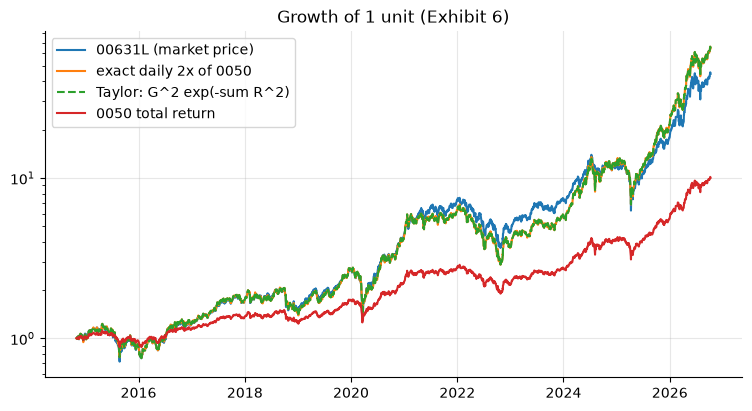

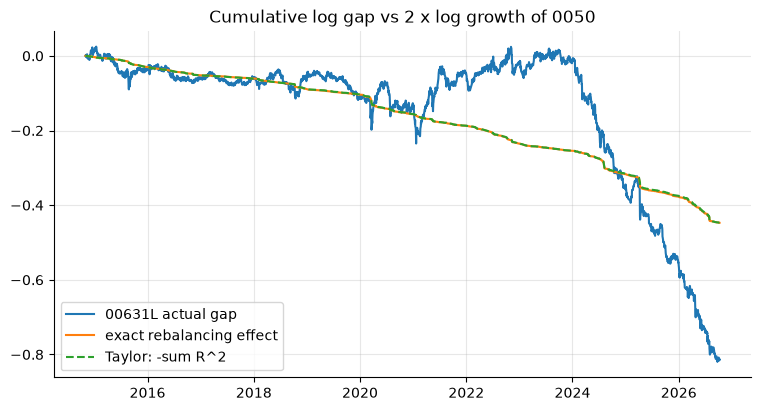

flat index: 2x -3.9%, 3x -11.3%


In [16]:
dates = np.concatenate([[np.datetime64("2014-10-31")], ret["date"].to_numpy()])
W0 = np.concatenate([[1], np.cumprod(1 + R)])
W2 = np.concatenate([[1], np.cumprod(1 + 2 * R)])
WT = np.concatenate([[1], np.cumprod(1 + R) ** 2 * np.exp(-np.cumsum(R**2))])
WL = np.concatenate([[1], np.cumprod(1 + RL)])
print(f"end values: 00631L {WL[-1]:.2f}, exact daily 2x {W2[-1]:.3f}, Taylor {WT[-1]:.3f}, 0050 {W0[-1]:.2f}")
fig, ax = plt.subplots()
ax.plot(dates, WL, label="00631L (market price)")
ax.plot(dates, W2, label="exact daily 2x of 0050")
ax.plot(dates, WT, "--", label="Taylor: G^2 exp(-sum R^2)")
ax.plot(dates, W0, label="0050 total return")
ax.set_yscale("log")
ax.set_title("Growth of 1 unit (Exhibit 6)")
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(dates, np.concatenate([[0], np.cumsum(np.log1p(RL) - 2 * np.log1p(R))]), label="00631L actual gap")
ax.plot(dates, np.concatenate([[0], np.cumsum(np.log1p(2 * R) - 2 * np.log1p(R))]), label="exact rebalancing effect")
ax.plot(dates, np.concatenate([[0], -np.cumsum(R**2)]), "--", label="Taylor: -sum R^2")
ax.set_title("Cumulative log gap vs 2 x log growth of 0050")
ax.legend()
plt.show()

# knowledge check: a flat index (G = 1) with RV = 0.04
print(f"flat index: 2x {math.exp(-0.04) - 1:.1%}, 3x {math.exp(-0.12) - 1:.1%}")

## Part 6 — TQQQ in 2022

Calendar-2022 returns use the adjusted close from 2021-12-31 to 2022-12-30; $L=3$, so the second-order drag coefficient is $L(L-1)/2=3$ and the third-order coefficient $(L^3-L)/3=8$.

TQQQ targets three times the daily return of the Nasdaq-100 Index (NDX), a price index that leaves dividends out. QQQ's adjusted close includes its dividends and its unadjusted close does not. The last lines therefore also measure the residual, and the benchmark $G^3e^{-3\,\mathrm{RV}}$, against the unadjusted close.

In [17]:
qt = (pl.read_csv(DATA / "QQQ_TQQQ_2022.csv")
        .filter(pl.col("date").is_between(pl.lit("2021-12-31"), pl.lit("2022-12-30"))).sort("date"))
qa, ta, qc = qt["qqq_adj"].to_numpy(), qt["tqqq_adj"].to_numpy(), qt["qqq_close"].to_numpy()
rq, rt = qa[1:] / qa[:-1] - 1, ta[1:] / ta[:-1] - 1
d3 = leverage_decomposition(rq, rt, 3)
G = qa[-1] / qa[0]
RVq = float(np.sum(rq**2))
print(f"QQQ {qa[0]} -> {qa[-1]}: {G - 1:.2%}   TQQQ {ta[0]} -> {ta[-1]}: {ta[-1] / ta[0] - 1:.2%}   "
      f"3 x QQQ {3 * (G - 1):.1%}")
print(f"RV {RVq:.4f}, sqrt(RV) {math.sqrt(RVq):.1%};  3 ln G {3 * math.log(G):.5f}, G^3 {G**3:.4f}")
print({name: round(float(v), 5) for name, v in d3.items()})   # Example 7
print(f"residual vs the exact effect {d3['residual']:.4f} ({math.expm1(d3['residual']):.1%} of value); "
      f"vs the second-order drag {d3['actual'] - d3['power'] - d3['taylor2']:.4f}")
print(f"before costs: Taylor {G**3 * math.exp(d3['taylor2']):.3f}, exact {G**3 * math.exp(d3['exact_drag']):.3f}")

# what the residual contains: fees and financing, then the dividends in QQQ's adjusted close
cost = 0.0086 + 2 * 0.0168   # expense ratio after waivers + two units at 2022's average fed funds rate
div_qqq = math.log(G) - math.log(qc[-1] / qc[0])
du = leverage_decomposition(qc[1:] / qc[:-1] - 1, rt, 3)
print(f"fees and financing {cost:.3f} ({cost / -d3['residual']:.0%} of the residual); "
      f"QQQ dividends {div_qqq:.4f} log points, x 3 = {3 * div_qqq:.3f}")
print(f"QQQ unadjusted {qc[0]} -> {qc[-1]}: residual {du['residual']:.3f}, "
      f"beyond fees and financing {-du['residual'] - cost:.3f}")
Gu3 = (qc[-1] / qc[0]) ** 3
bench_u = Gu3 * math.exp(du["taylor2"])
print(f"benchmark on the unadjusted closes: {Gu3:.4f} x {math.exp(du['taylor2']):.3f} = {bench_u:.3f}, "
      f"a {1 - bench_u:.1%} loss ({1 - Gu3 * math.exp(du['exact_drag']):.1%} with the exact effect)")

QQQ 386.63 -> 260.68: -32.58%   TQQQ 39.55 -> 8.27: -79.09%   3 x QQQ -97.7%
RV 0.1030, sqrt(RV) 32.1%;  3 ln G -1.18252, G^3 0.3065
{'power': -1.18252, 'exact_drag': -0.31325, 'taylor2': -0.309, 'taylor3': -0.31068, 'taylor4': -0.31325, 'residual': -0.06916, 'actual': -1.56493}
residual vs the exact effect -0.0692 (-6.7% of value); vs the second-order drag -0.0734
before costs: Taylor 0.225, exact 0.224
fees and financing 0.042 (61% of the residual); QQQ dividends 0.0074 log points, x 3 = 0.022
QQQ unadjusted 397.85 -> 266.28: residual -0.047, beyond fees and financing 0.005
benchmark on the unadjusted closes: 0.2998 x 0.734 = 0.220, a 78.0% loss (78.1% with the exact effect)


## Part 7 — Duration and convexity

A 10-year bond with a 2% annual coupon, priced at a 2% yield. Duration and convexity come from the exact derivatives of $P(y)$.

In [18]:
def price(y, coupon=0.02, periods=10, face=100.0):
    return sum(coupon * face / (1 + y) ** t for t in range(1, periods + 1)) + face / (1 + y) ** periods

y0 = 0.02
P0 = price(y0)
dP = -sum(t * 2 / (1 + y0) ** (t + 1) for t in range(1, 11)) - 10 * 100 / (1 + y0) ** 11
d2P = sum(t * (t + 1) * 2 / (1 + y0) ** (t + 2) for t in range(1, 11)) + 110 * 100 / (1 + y0) ** 12
Dmod, C = -dP / P0, d2P / P0
print(f"P0={P0:.4f}  Dmod={Dmod:.6f}  C={C:.6f}")
pl.DataFrame([{"dy_bp": dy * 1e4, "exact": price(y0 + dy) / P0 - 1, "duration": -Dmod * dy,
               "duration+convexity": -Dmod * dy + 0.5 * C * dy * dy} for dy in (0.01, -0.01, 0.03)])   # Example 8

P0=100.0000  Dmod=8.982585  C=93.995462


dy_bp,exact,duration,duration+convexity
f64,f64,f64,f64
100.000000,-0.085302,-0.089826,-0.085126
-100.000000,0.094713,0.089826,0.094526
300.000000,-0.231652,-0.269478,-0.227180


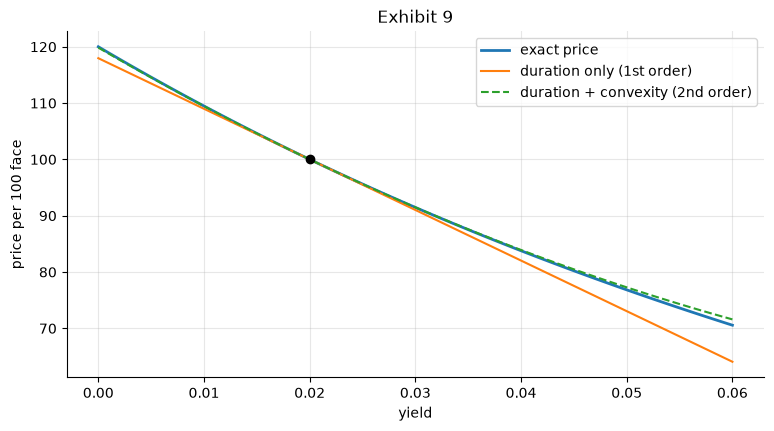

In [19]:
yg = np.linspace(0.0, 0.06, 121)
fig, ax = plt.subplots()
ax.plot(yg, [price(v) for v in yg], lw=2, label="exact price")
ax.plot(yg, P0 * (1 - Dmod * (yg - y0)), label="duration only (1st order)")
ax.plot(yg, P0 * (1 - Dmod * (yg - y0) + 0.5 * C * (yg - y0) ** 2), "--", label="duration + convexity (2nd order)")
ax.plot([y0], [P0], "o", color="black")
ax.set_xlabel("yield")
ax.set_ylabel("price per 100 face")
ax.set_title("Exhibit 9")
ax.legend()
plt.show()

## Part 8 — Practice-problem solutions (computational) and an extension

In [20]:
print("PP2 ", f"T2={0.08 - 0.08**2 / 2:.4f}  exact={math.log(1.08):.5f}  third-order term={0.08**3 / 3:.5f}")
print("PP3 ", f"ln(0.92)={math.log1p(-0.08):.7f}  T2={taylor_log1p(-0.08, 2):.7f}  bound={bound_log1p(-0.08, 2):.7f}")
pp4 = np.array([0.30, -0.20, 0.10])
print("PP4 ", f"geo={np.prod(1 + pp4) ** (1 / 3) - 1:.4%}  approx={pp4.mean() - pp4.var() / 2:.4%}  "
      f"with the sample variance {pp4.mean() - pp4.var(ddof=1) / 2:.4%}")
print("PP6 ", f"geo={math.sqrt(1.6 * 0.6) - 1:.3%}  approx={0.10 - 0.5**2 / 2:.3%}")
print("PP7 ", f"index={1.1 * 0.9 - 1:.2%}  fund={1.2 * 0.8 - 1:.2%}  taylor={(1.1 * 0.9) ** 2 * math.exp(-0.02) - 1:.2%}  "
      f"drag={math.log(0.96) - 2 * math.log(0.99):.4f}")
print("PP8 ", f"{1.2**3 * math.exp(-3 * 0.09) - 1:.2%}")
for y, Gp, RVp in ((2017, 1.1813, 0.0088), (2015, 0.9369, 0.0266)):   # the inputs printed in the problem
    Gy = 1 + annual.filter(pl.col("year") == y)["R_0050"][0]
    RVy = float(np.sum(R[(ret["date"].dt.year() == y).to_numpy()] ** 2))
    assert (round(Gy, 4), round(RVy, 4)) == (Gp, RVp)
    print(f"PP9  {y}: G={Gp} RV={RVp}  |1-1/G|={abs(1 - 1 / Gp):.3f}  sqrt(RV)={math.sqrt(RVp):.3f}")
print("PP10", f"{-7.5 * 0.015 + 0.5 * 70 * 0.015**2:.3%}")
print("PP12", f"exact={math.log(2) / math.log1p(0.06):.3f}  ln2/R+ln2/2={math.log(2) / 0.06 + math.log(2) / 2:.3f}  "
      f"0.693/R+0.347={0.693 / 0.06 + 0.347:.3f}")
print("PP13", f"exact={1.03 / 1.025 - 1:.4%}  first={0.005:.4%}  second={0.005 - 0.025 * 0.005:.4%}")
m = ret["date"].dt.year().is_between(2020, 2023).to_numpy()
pp14 = leverage_decomposition(R[m], RL[m], 2)
print("PP14", {name: round(float(v), 5) for name, v in pp14.items()}, f"00631L {math.expm1(pp14['actual']):+.1%}")

PP2  T2=0.0768  exact=0.07696  third-order term=0.00017
PP3  ln(0.92)=-0.0833816  T2=-0.0832000  bound=0.0002192
PP4  geo=4.5864%  approx=4.5556%  with the sample variance 3.5000%
PP6  geo=-2.020%  approx=-2.500%
PP7  index=-1.00%  fund=-4.00%  taylor=-3.93%  drag=-0.0207
PP8  31.91%
PP9  2017: G=1.1813 RV=0.0088  |1-1/G|=0.153  sqrt(RV)=0.094
PP9  2015: G=0.9369 RV=0.0266  |1-1/G|=0.067  sqrt(RV)=0.163
PP10 -10.463%
PP12 exact=11.896  ln2/R+ln2/2=11.899  0.693/R+0.347=11.897
PP13 exact=0.4878%  first=0.5000%  second=0.4875%
PP14 {'power': 0.94274, 'exact_drag': -0.15035, 'taylor2': -0.15086, 'taylor3': -0.14979, 'taylor4': -0.15036, 'residual': 0.2456, 'actual': 1.03799} 00631L +182.4%


### Extension: the inverse fund

For an inverse fund $L=-1$, the drag coefficient $L(L-1)/2$ equals $1$: a daily −1× fund suffers the **same** variance drag as a daily 2× fund. Fetch Yuanta Taiwan 50 Bear −1X (00632R) and test (3.11) with $L=-1$. The helper below downloads data from the FinMind API with your own token (`FINMIND_TOKEN` environment variable) and the standard library's `urllib`; it queries one year at a time, which keeps each query under FinMind's 500-row limit.

In [21]:
import json
import os
import urllib.parse
import urllib.request


def finmind(dataset, data_id, start, end):
    token = os.environ["FINMIND_TOKEN"]
    out = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        params = {"dataset": dataset, "data_id": data_id, "start_date": max(start, f"{y}-01-01"),
                  "end_date": min(end, f"{y}-12-31"), "token": token}
        req = urllib.request.Request("https://api.finmindtrade.com/api/v4/data?" + urllib.parse.urlencode(params),
                                     headers={"Authorization": f"Bearer {token}"})
        with urllib.request.urlopen(req, timeout=30) as resp:
            out.extend(json.load(resp).get("data", []))
    return pl.DataFrame(out)

# inv = finmind("TaiwanStockPrice", "00632R", "2015-01-01", "2026-10-08")   # uncomment to run